In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (
    train_test_split, KFold, GridSearchCV, cross_val_score
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score
)

RANDOM_STATE = 42
sns.set_style("whitegrid")

df = pd.read_csv("calorie_dataset.csv")
df.head()

,protein_g,carbs_g,fat_g,fiber_g,sugar_g,calories,calorie_class
0,22.5,65.2,13.7,9.9,26.7,479.0,medium
1,15.9,20.7,16.8,7.6,15.0,316.0,low
2,28.3,62.4,14.5,10.8,15.3,524.0,medium
3,23.3,18.6,7.9,17.0,0.2,250.0,low
4,30.8,55.1,31.9,12.5,7.2,602.0,medium


In [ ]:
print("Shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())

df.describe().T

Shape: (5000, 7)

Dtypes:
 protein_g        float64
carbs_g          float64
fat_g            float64
fiber_g          float64
sugar_g          float64
calories         float64
calorie_class     object
dtype: object

Missing values:
 protein_g        0
carbs_g          0
fat_g            0
fiber_g          0
sugar_g          0
calories         0
calorie_class    0
dtype: int64

Duplicates: 0


,count,mean,std,min,25%,50%,75%,max
protein_g,5000.0,25.07672,9.907564,0.0,18.4,25.10,31.700,64.3
carbs_g,5000.0,49.85042,20.071407,0.0,36.3,49.65,63.525,120.6
fat_g,5000.0,20.10528,7.933298,0.0,14.7,20.10,25.400,47.4
fiber_g,5000.0,8.10362,3.923217,0.0,5.3,8.10,10.800,25.9
sugar_g,5000.0,15.08898,9.298863,0.0,8.0,14.90,21.500,51.1
calories,5000.0,480.45580,117.948845,56.0,400.0,480.00,561.250,975.0


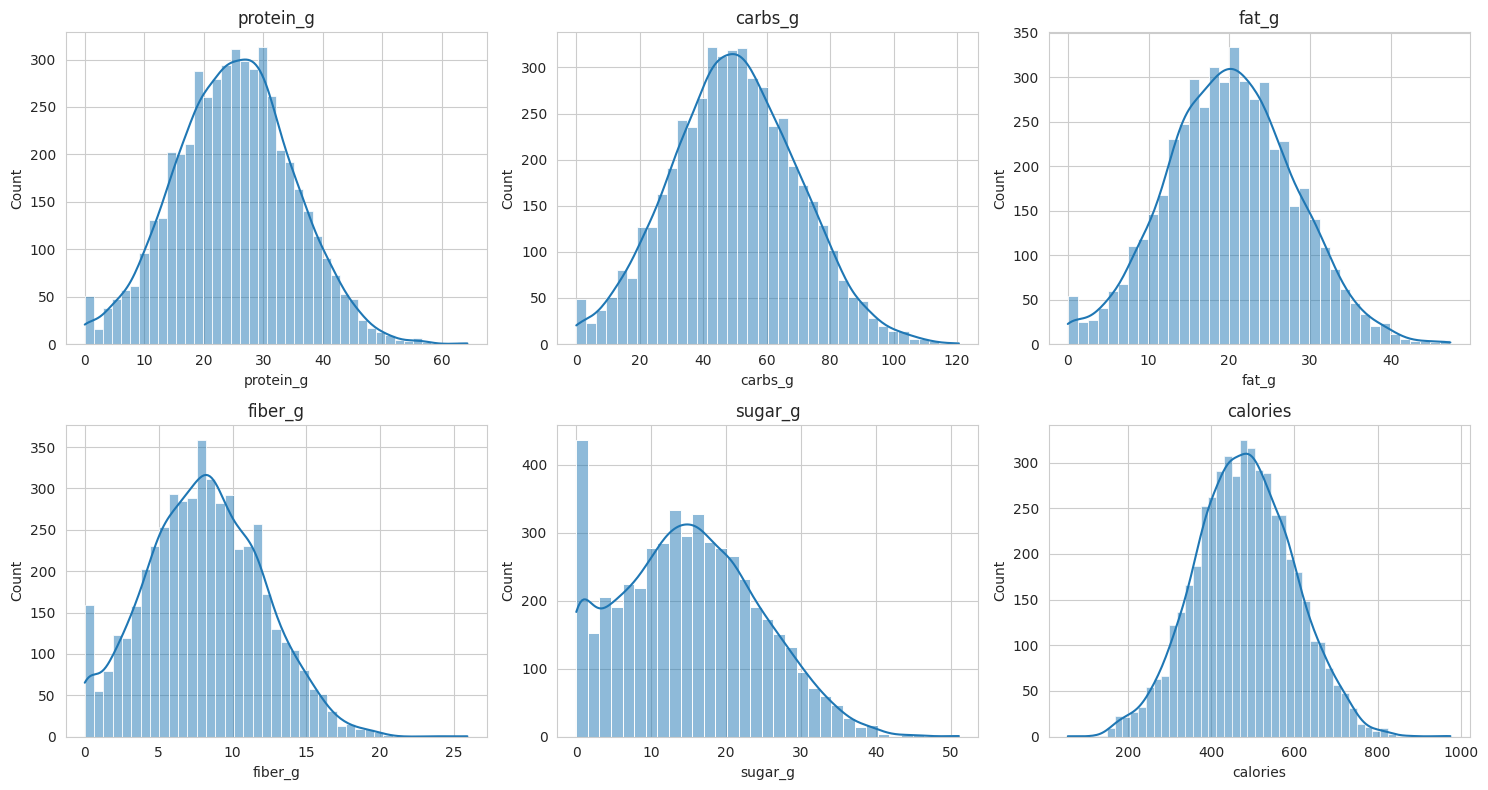

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
cols = ["protein_g", "carbs_g", "fat_g", "fiber_g", "sugar_g", "calories"]
for ax, col in zip(axes.ravel(), cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

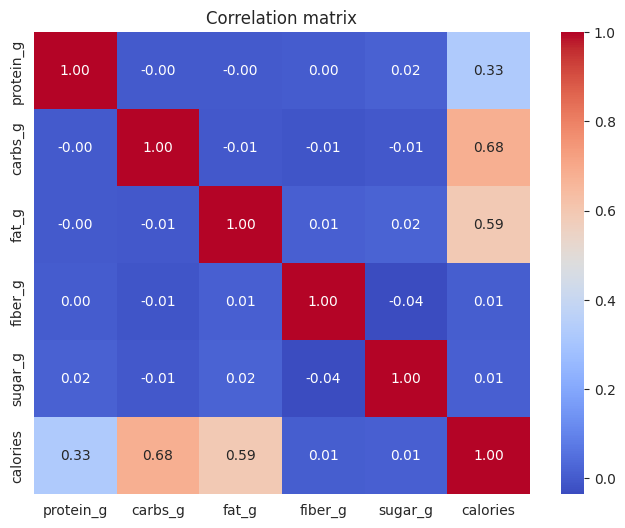

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation matrix")
plt.show()

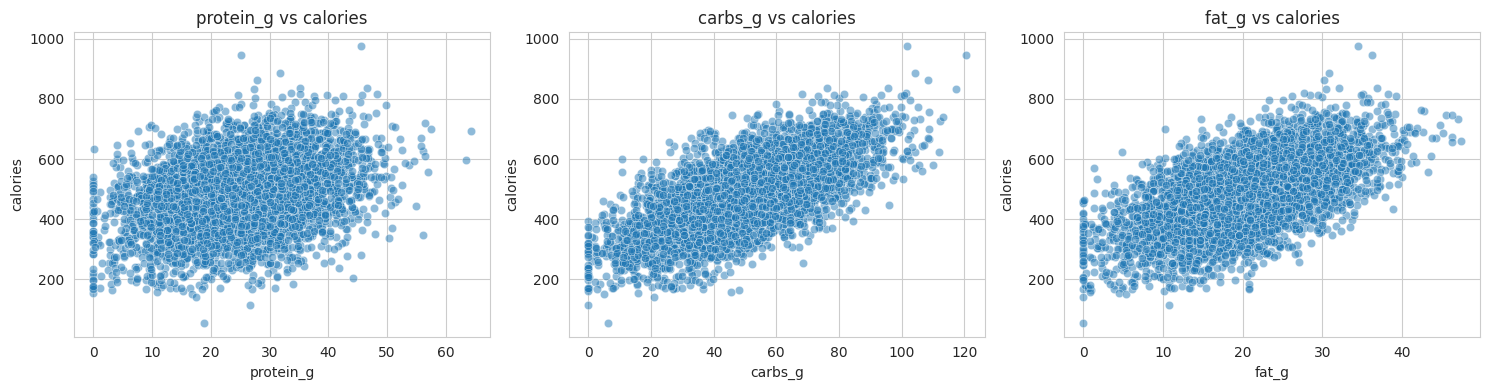

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["protein_g", "carbs_g", "fat_g"]):
    sns.scatterplot(data=df, x=col, y="calories", ax=ax, alpha=0.5)
    ax.set_title(f"{col} vs calories")
plt.tight_layout()
plt.show()

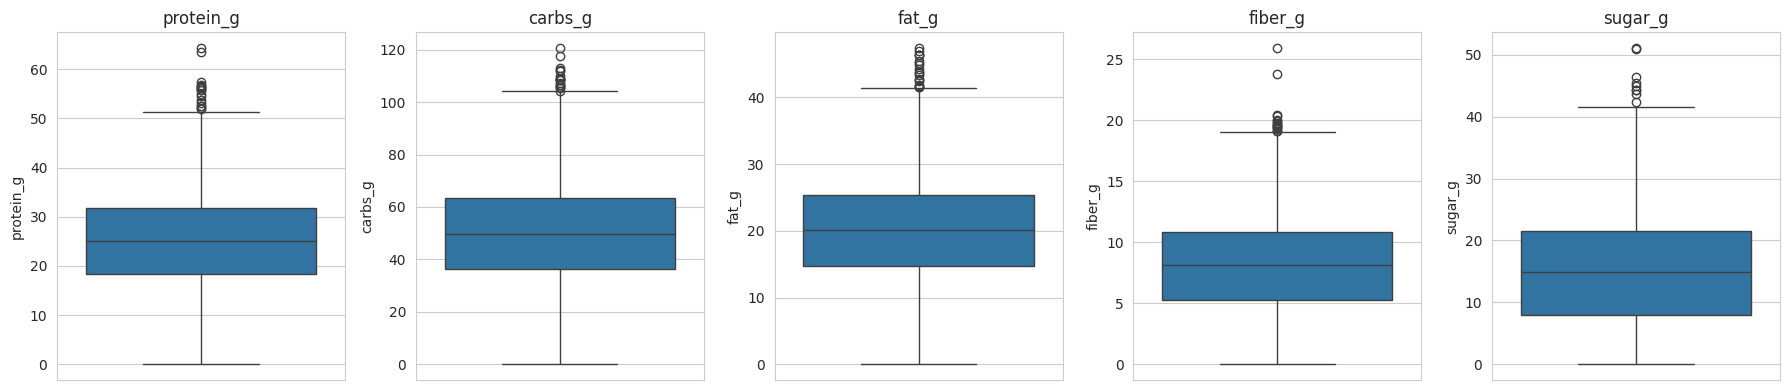

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, ["protein_g", "carbs_g", "fat_g", "fiber_g", "sugar_g"]):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [ ]:
features = ["protein_g", "carbs_g", "fat_g", "fiber_g", "sugar_g"]
X = df[features]
y = df["calories"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (4000, 5) Test: (1000, 5)


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[("num", StandardScaler(), features)]
)

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [ ]:
lr_pipe = Pipeline([
    ("pre", preprocessor),
    ("model", LinearRegression())
])

lr_rmse = -cross_val_score(lr_pipe, X_train, y_train, cv=cv,
                           scoring="neg_root_mean_squared_error")
lr_mae  = -cross_val_score(lr_pipe, X_train, y_train, cv=cv,
                           scoring="neg_mean_absolute_error")
lr_r2   =  cross_val_score(lr_pipe, X_train, y_train, cv=cv, scoring="r2")

print("Linear Regression")
print("CV RMSE:", lr_rmse.mean(), "±", lr_rmse.std())
print("CV MAE :", lr_mae.mean(),  "±", lr_mae.std())
print("CV R²  :", lr_r2.mean(),   "±", lr_r2.std())

Linear Regression
CV RMSE: 30.039295448345193 ± 0.38418099231497976
CV MAE : 23.910297420167286 ± 0.41320706106586735
CV R²  : 0.9357296778089488 ± 0.0025545356715396413


In [ ]:
dt_pipe = Pipeline([
    ("pre", preprocessor),
    ("model", DecisionTreeRegressor(random_state=RANDOM_STATE))
])

In [ ]:
dt_param_grid = {
    "model__max_depth": [3, 5, 7, 10, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [None, "sqrt", "log2"]
}

In [ ]:
dt_grid = GridSearchCV(
    dt_pipe,
    dt_param_grid,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("Best params:", dt_grid.best_params_)
print("Best CV RMSE:", -dt_grid.best_score_)

Best params: {'model__max_depth': 10, 'model__max_features': None, 'model__min_samples_leaf': 4, 'model__min_samples_split': 10}
Best CV RMSE: 40.993900721165836


In [ ]:
best_dt = dt_grid.best_estimator_

dt_rmse = -cross_val_score(best_dt, X_train, y_train, cv=cv,
                           scoring="neg_root_mean_squared_error")
dt_mae  = -cross_val_score(best_dt, X_train, y_train, cv=cv,
                           scoring="neg_mean_absolute_error")
dt_r2   =  cross_val_score(best_dt, X_train, y_train, cv=cv, scoring="r2")

print("Decision Tree")
print("CV RMSE:", dt_rmse.mean(), "±", dt_rmse.std())
print("CV MAE :", dt_mae.mean(),  "±", dt_mae.std())
print("CV R²  :", dt_r2.mean(),   "±", dt_r2.std())

Decision Tree
CV RMSE: 40.993900721165836 ± 0.69111142959841
CV MAE : 32.40407879408702 ± 0.5047262652088075
CV R²  : 0.8803560001915673 ± 0.00380808116479465


In [ ]:
rf_pipe = Pipeline([
    ("pre", preprocessor),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE))
])

rf_param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [5, 10, None],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [None, "sqrt", "log2"]
}

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, None],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt", "log2"]
}

rf_search = RandomizedSearchCV(
    rf_pipe,
    rf_param_grid,
    n_iter=10,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

rf_search.fit(X_train, y_train)

print("Best params:", rf_search.best_params_)
print("Best CV RMSE:", -rf_search.best_score_)

Best params: {'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': None}
Best CV RMSE: 34.411700221465246


In [ ]:
best_rf = rf_grid.best_estimator_

rf_rmse = -cross_val_score(best_rf, X_train, y_train, cv=cv,
                           scoring="neg_root_mean_squared_error")
rf_mae  = -cross_val_score(best_rf, X_train, y_train, cv=cv,
                           scoring="neg_mean_absolute_error")
rf_r2   =  cross_val_score(best_rf, X_train, y_train, cv=cv, scoring="r2")

print("Random Forest")
print("CV RMSE:", rf_rmse.mean(), "±", rf_rmse.std())
print("CV MAE :", rf_mae.mean(),  "±", rf_mae.std())
print("CV R²  :", rf_r2.mean(),   "±", rf_r2.std())

Random Forest
CV RMSE: 34.411700221465246 ± 0.7679240191964287
CV MAE : 27.063266249999998 ± 0.49421812466131737
CV R²  : 0.9156718642838424 ± 0.0037086221018918612


In [ ]:
lr_pipe.fit(X_train, y_train)

y_pred = lr_pipe.predict(X_test)

test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_mae  = mean_absolute_error(y_test, y_pred)
test_r2   = r2_score(y_test, y_pred)

print("Linear Regression — Test metrics")
print("RMSE:", test_rmse)
print("MAE :", test_mae)
print("R²  :", test_r2)

Linear Regression — Test metrics
RMSE: 29.667068194316265
MAE : 24.055351050157864
R²  : 0.93335392180662
